In [6]:
"""
Phase 2C: Vectorisation vs Element-Wise vs JIT

You identified the bottleneck in Phase 1. Now you fix it.
The same operation, implemented four ways. Which one wins?

This section answers: why is NumPy fast? When does Numba help?
What is the practical limit of parallel speedup?
"""

import numpy as np
import time
import matplotlib.pyplot as plt
from numba import njit, prange


def gram_elementwise(X):
    """
    Compute G = X^T @ X using triple-nested Python loops.
    This is the slow baseline. It exists to make the speedup dramatic.
    """
    m, n = X.shape
    G = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            s = 0.0
            for k in range(m):
                s += X[k, i] * X[k, j]
            G[i, j] = s
    return G


def gram_vectorised(X):
    """
    Compute G = X^T @ X using NumPy vectorisation.
    One line. BLAS does the work.
    """
    return X.T @ X


@njit
def gram_numba_serial(X):
    """
    Compute G = X^T @ X with Numba JIT (serial).
    Same loops as elementwise, but compiled.
    """
    m, n = X.shape
    G = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            s = 0.0
            for k in range(m):
                s += X[k, i] * X[k, j]
            G[i, j] = s

    return G


@njit(parallel=True)
def gram_numba_parallel(X):
    """
    Compute G = X^T @ X with Numba JIT (parallel).
    Parallelise the outer loop with prange.
    """
    m, n = X.shape
    G = np.zeros((n, n))

    for i in prange(n):
        for j in range(n):
            s = 0.0
            for k in range(m):
                s += X[k, i] * X[k, j]
            G[i, j] = s

    return G


def benchmark_versions(X, runs=5):
    """
    Benchmark all four implementations.
    Returns dict mapping version -> (mean_time, std_time)
    """
    results = {}

    # 1. Element-wise (skip for large matrices)
    if X.shape[0] * X.shape[1] < 2_000_000:
        times = []
        for _ in range(runs):
            t0 = time.perf_counter()
            _ = gram_elementwise(X)
            t1 = time.perf_counter()
            times.append(t1 - t0)
        results["elementwise"] = (np.mean(times), np.std(times))
        print(f"Element-wise: {results['elementwise'][0]:.4f}s")
    else:
        print("Element-wise: SKIPPED (too large)")

    # 2. Vectorised
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        _ = gram_vectorised(X)
        t1 = time.perf_counter()
        times.append(t1 - t0)
    results["vectorised"] = (np.mean(times), np.std(times))
    print(f"Vectorised:   {results['vectorised'][0]:.4f}s")

    # 3. Numba serial (warmup critical!)
    print("Warming up Numba serial...")
    _ = gram_numba_serial(X)
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        _ = gram_numba_serial(X)
        t1 = time.perf_counter()
        times.append(t1 - t0)
    results["numba_serial"] = (np.mean(times), np.std(times))
    print(f"Numba serial: {results['numba_serial'][0]:.4f}s")

    # 4. Numba parallel (warmup critical!)
    print("Warming up Numba parallel...")
    _ = gram_numba_parallel(X)
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        _ = gram_numba_parallel(X)
        t1 = time.perf_counter()
        times.append(t1 - t0)
    results["numba_parallel"] = (np.mean(times), np.std(times))
    print(f"Numba parallel: {results['numba_parallel'][0]:.4f}s")

    return results


def plot_speedup(results):
    """
    Bar plot: speedup relative to element-wise baseline.
    This is the "1000x speedup" figure for your report.
    """
    baseline_time = results.get("elementwise", (1.0, 0))[0]

    names = []
    speedups = []
    for name, (mean_t, _) in results.items():
        if name != "elementwise":
            names.append(name)
            speedups.append(baseline_time / mean_t)

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.bar(names, speedups, color=['steelblue', 'forestgreen', 'coral'])
    ax.set_ylabel('Speedup vs. Element-wise')
    ax.set_title('Vectorisation & JIT Speedup')
    ax.axhline(y=1, color='black', linestyle='--', alpha=0.5)
    ax.grid(axis='y', alpha=0.3)

    for bar, speedup in zip(bars, speedups):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{speedup:.0f}x',
                ha='center', va='bottom', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.savefig('vectorisation_speedup3.png', dpi=150, bbox_inches='tight')
    print("Saved: vectorisation_speedup3.png")


def verify_correctness():
    """Check all four methods produce the same result."""
    np.random.seed(42)
    X = np.random.randn(100, 50).astype(np.float64)

    G_elem = gram_elementwise(X)
    G_vec = gram_vectorised(X)
    G_nbs = gram_numba_serial(X)
    G_nbp = gram_numba_parallel(X)

    assert np.allclose(G_elem, G_vec, rtol=1e-5)
    assert np.allclose(G_elem, G_nbs, rtol=1e-5)
    assert np.allclose(G_elem, G_nbp, rtol=1e-5)
    print("All implementations produce correct results!")




Phase 2C: Vectorisation vs Element-Wise vs JIT

Verifying correctness...
All implementations produce correct results!

Benchmarking...
Matrix: (500, 300)
Element-wise: 14.4123s
Vectorised:   0.0016s
Warming up Numba serial...
Numba serial: 0.0591s
Warming up Numba parallel...
Numba parallel: 0.0610s
Saved: vectorisation_speedup3.png

YOUR TASKS:
1. Implement all four versions correctly
2. Measure speedup for different matrix sizes
3. Discuss: why does NumPy beat pure Python?
4. Discuss: when does Numba beat NumPy? When does it lose?
5. Discuss: what limits parallel speedup? (Amdahl's Law)


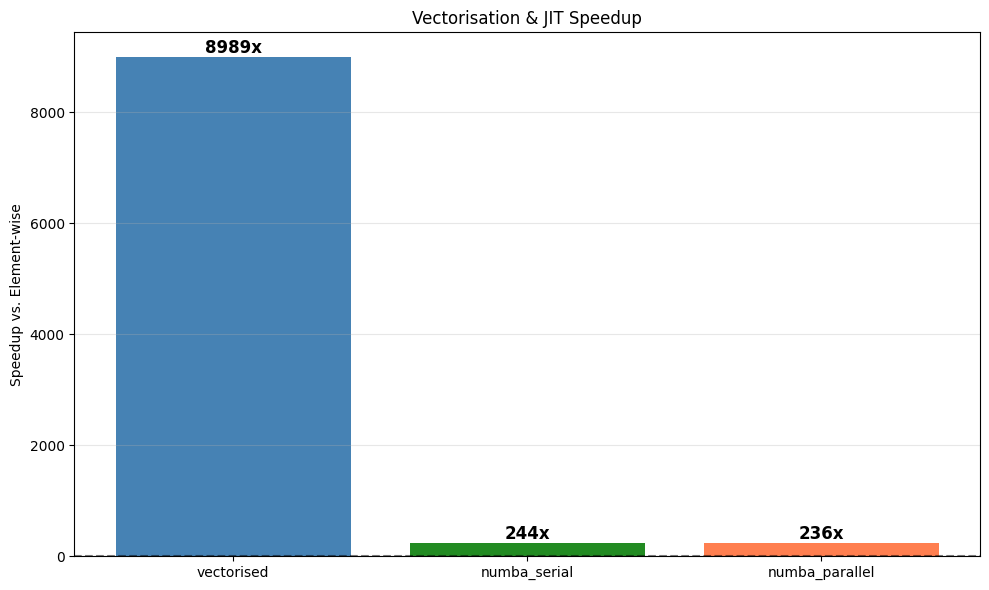

In [3]:
if __name__ == "__main__":
    print("=" * 60)
    print("Phase 2C: Vectorisation vs Element-Wise vs JIT")
    print("=" * 60)

    # Verify first
    print("\nVerifying correctness...")
    verify_correctness()

    # Benchmark
    print("\n" + "=" * 60)
    print("Benchmarking...")
    print("=" * 60)

    np.random.seed(42)
    #matrix
    X = np.random.randn(500, 300).astype(np.float64)
    print(f"Matrix: {X.shape}")

    results = benchmark_versions(X, runs=5)
    plot_speedup(results)

    print("\n" + "=" * 60)
    print("YOUR TASKS:")
    print("1. Implement all four versions correctly")
    print("2. Measure speedup for different matrix sizes")
    print("3. Discuss: why does NumPy beat pure Python?")
    print("4. Discuss: when does Numba beat NumPy? When does it lose?")
    print("5. Discuss: what limits parallel speedup? (Amdahl's Law)")
    print("=" * 60)


Phase 2C: Vectorisation vs Element-Wise vs JIT

Verifying correctness...
All implementations produce correct results!

Benchmarking...
Matrix: (1000, 300)
Element-wise: 30.5480s
Vectorised:   0.0028s
Warming up Numba serial...
Numba serial: 0.1164s
Warming up Numba parallel...
Numba parallel: 0.1211s
Saved: vectorisation_speedup3.png

YOUR TASKS:
1. Implement all four versions correctly
2. Measure speedup for different matrix sizes
3. Discuss: why does NumPy beat pure Python?
4. Discuss: when does Numba beat NumPy? When does it lose?
5. Discuss: what limits parallel speedup? (Amdahl's Law)


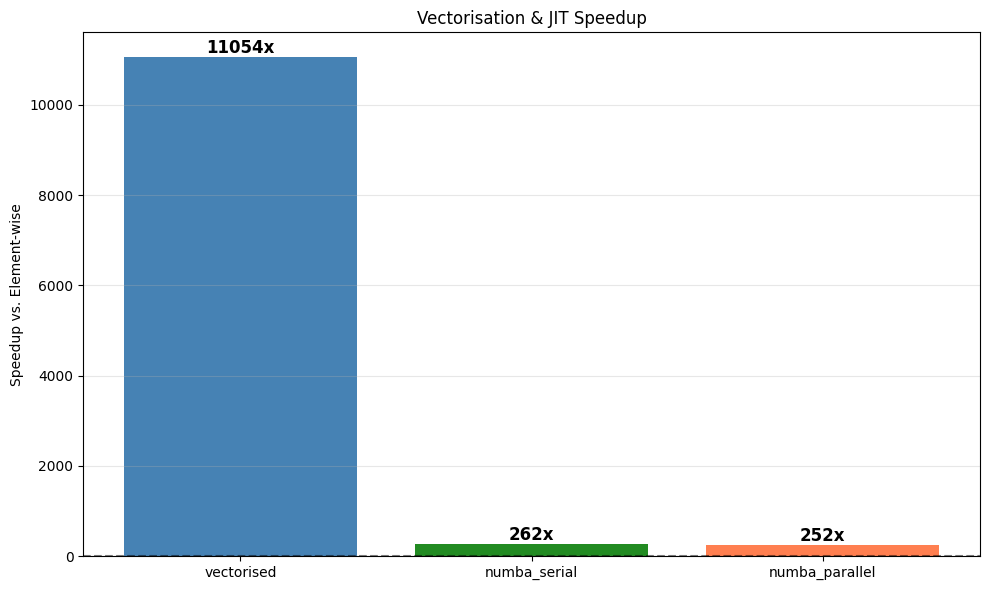

In [4]:
if __name__ == "__main__":
    print("=" * 60)
    print("Phase 2C: Vectorisation vs Element-Wise vs JIT")
    print("=" * 60)

    # Verify first
    print("\nVerifying correctness...")
    verify_correctness()

    # Benchmark
    print("\n" + "=" * 60)
    print("Benchmarking...")
    print("=" * 60)

    np.random.seed(42)
    #matrix
    X = np.random.randn(1000, 300).astype(np.float64)
    print(f"Matrix: {X.shape}")

    results = benchmark_versions(X, runs=5)
    plot_speedup(results)

    print("\n" + "=" * 60)
    print("YOUR TASKS:")
    print("1. Implement all four versions correctly")
    print("2. Measure speedup for different matrix sizes")
    print("3. Discuss: why does NumPy beat pure Python?")
    print("4. Discuss: when does Numba beat NumPy? When does it lose?")
    print("5. Discuss: what limits parallel speedup? (Amdahl's Law)")
    print("=" * 60)


Phase 2C: Vectorisation vs Element-Wise vs JIT

Verifying correctness...
All implementations produce correct results!

Benchmarking...
Matrix: (2500, 300)
Element-wise: 79.6920s
Vectorised:   0.0069s
Warming up Numba serial...
Numba serial: 0.3099s
Warming up Numba parallel...
Numba parallel: 0.3705s
Saved: vectorisation_speedup3.png

YOUR TASKS:
1. Implement all four versions correctly
2. Measure speedup for different matrix sizes
3. Discuss: why does NumPy beat pure Python?
4. Discuss: when does Numba beat NumPy? When does it lose?
5. Discuss: what limits parallel speedup? (Amdahl's Law)


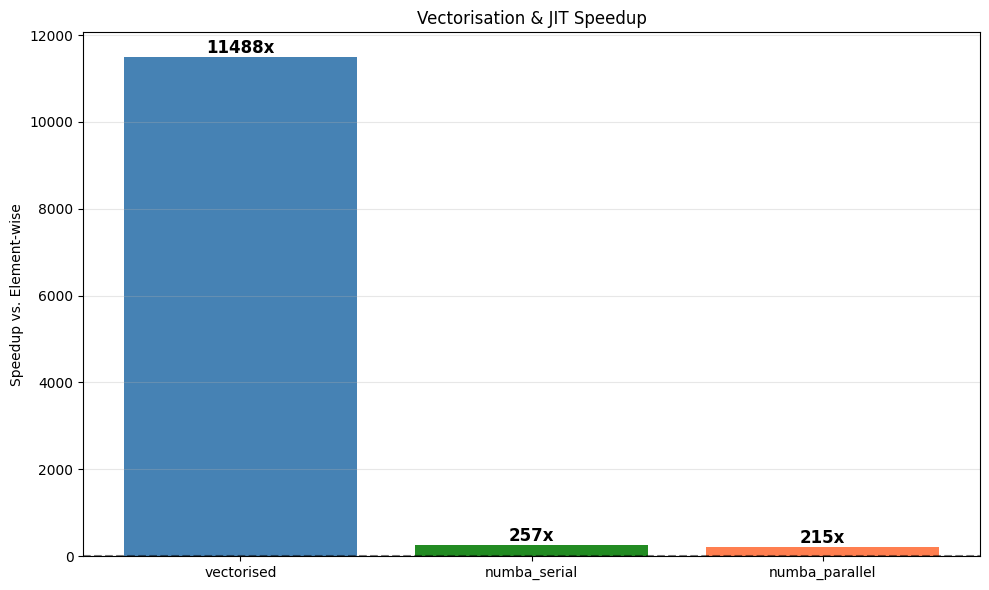

In [5]:
if __name__ == "__main__":
    print("=" * 60)
    print("Phase 2C: Vectorisation vs Element-Wise vs JIT")
    print("=" * 60)

    # Verify first
    print("\nVerifying correctness...")
    verify_correctness()

    # Benchmark
    print("\n" + "=" * 60)
    print("Benchmarking...")
    print("=" * 60)

    np.random.seed(42)
    #matrix
    X = np.random.randn(2500, 300).astype(np.float64)
    print(f"Matrix: {X.shape}")

    results = benchmark_versions(X, runs=5)
    plot_speedup(results)

    print("\n" + "=" * 60)
    print("YOUR TASKS:")
    print("1. Implement all four versions correctly")
    print("2. Measure speedup for different matrix sizes")
    print("3. Discuss: why does NumPy beat pure Python?")
    print("4. Discuss: when does Numba beat NumPy? When does it lose?")
    print("5. Discuss: what limits parallel speedup? (Amdahl's Law)")
    print("=" * 60)


Phase 2C: Vectorisation vs Element-Wise vs JIT

Verifying correctness...
All implementations produce correct results!

Benchmarking...
Matrix: (5000, 300)
Element-wise: 160.9534s
Vectorised:   0.0132s
Warming up Numba serial...
Numba serial: 0.9574s
Warming up Numba parallel...
Numba parallel: 1.1350s
Saved: vectorisation_speedup3.png

YOUR TASKS:
1. Implement all four versions correctly
2. Measure speedup for different matrix sizes
3. Discuss: why does NumPy beat pure Python?
4. Discuss: when does Numba beat NumPy? When does it lose?
5. Discuss: what limits parallel speedup? (Amdahl's Law)


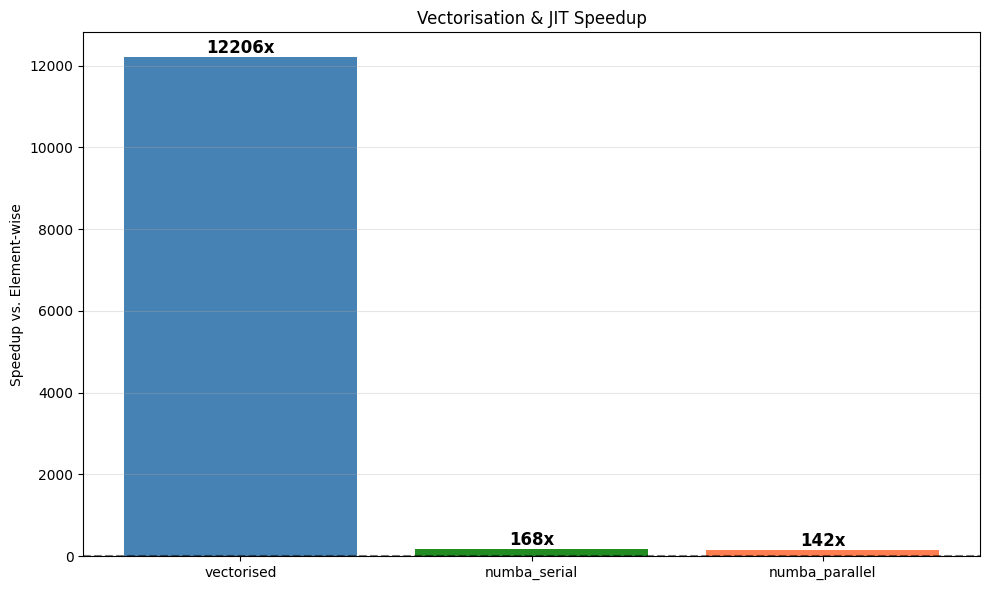

In [7]:
if __name__ == "__main__":
    print("=" * 60)
    print("Phase 2C: Vectorisation vs Element-Wise vs JIT")
    print("=" * 60)

    # Verify first
    print("\nVerifying correctness...")
    verify_correctness()

    # Benchmark
    print("\n" + "=" * 60)
    print("Benchmarking...")
    print("=" * 60)

    np.random.seed(42)
    #matrix
    X = np.random.randn(5000, 300).astype(np.float64)
    print(f"Matrix: {X.shape}")

    results = benchmark_versions(X, runs=5)
    plot_speedup(results)

    print("\n" + "=" * 60)
    print("YOUR TASKS:")
    print("1. Implement all four versions correctly")
    print("2. Measure speedup for different matrix sizes")
    print("3. Discuss: why does NumPy beat pure Python?")
    print("4. Discuss: when does Numba beat NumPy? When does it lose?")
    print("5. Discuss: what limits parallel speedup? (Amdahl's Law)")
    print("=" * 60)
